# Comparative Reliability Performance of N-Body Simulation under Hamiltonian Framework Applying Barnes-Hut Trees
Within the realms of modern orbital mechanics application of Barnes-Hut trees is a common practice for large N-Body simulations. The project describes the creation of a C++ and R tool to simulate the problem assessing reliability of the Barnes-Hut trees for cosmological applications via application of symplectic and non-symplectic integration schemes.

## About The Notebook
This notebook is a simulation prototype, that shows fast results and validation of said results using Python.
It will be kept in a dated entry order expanding each individual feature for a later transfer to C++ and R framework.
It will also comply with the project's gantt chart of progress.

Please bear in mind that the function and variable names follow a certain pattern:
- Integrators and their daughter functions: `operation_integrator_order`
- Mathematical equations take their literal mathematical names, where numerator is a numerator, product is a product, etc.

## Setting the Environment and Creating Velocity Verlet 4th Order (28/10/26)

In [7]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import random as rnd

# Randomisation Seed
rnd.seed(256)

# Constants
G_const = 6.67e-11
yoshida_x0 = -(2**(1/3))/(2-(2**(1/3)))
yoshida_x1 = (1/(2-(2**(1/3))))

In [8]:
"""
Creating helper functions to help with force evaluation later.
"""

# Find Euclidian distance between two bodies
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
def euclidian_distance(obj_a, obj_b):
    return np.linalg.norm(obj_a.r - obj_b.r)

# Find initial velocity
# obj – individual object with accessible properties
# G – constant of gravitational attraction
# distance – previously found Euclidian distance
def vel_init(obj, G, distance):
    return rnd.random() * np.sqrt((G*obj.m) / distance)  # random variable in the beginning is used to create random orbit eccentricities (no ejection)

# Get a perpendicular vector
def get_perpendicular(v):
    x, y, z = v
    if x != 0 or y != 0:
        perp = np.array([-y, x, 0.0], dtype=float)
    else:
        perp = np.array([0.0, 1.0, 0.0], dtype=float)

    return perp

# Find velocity direction
# Essentially convert scalar velocity into vector velocity
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
# distance – previously found Euclidian distance
# v – scalar velocity
def vel_direction(obj_a, obj_b, distance, v):
    radius_vector = obj_b.r - obj_a.r
    perp_vector = get_perpendicular(radius_vector)
    unit_perp_vector = perp_vector / np.linalg.norm(perp_vector)    # normalise by its own length

    return v * unit_perp_vector


# Compute Gravitational Acceleration of All Bodies acting on i
# G – the constant of gravitational attraction
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
def acc(G, bod_obj, e):
    N = len(bod_obj)    
    accelerations = [np.zeros(3) for _ in range(N)]     # initialise an array to hold acceleration vectors for all bodies

    # Sigma operation
    # Loop over every body i
    for i in range(N):
        a_i = np.zeros(3)   # net acceleration vector on body i

        # Sum gravitational pull from every other body j
        for j in range(N):
            if i == j:
                continue    # idiot-proofing self-interaction

            # Compute displacement from i to j
            r_ij = bod_obj[i].r - bod_obj[j].r

            # Scalar distance squared
            dist_sq = np.sum(r_ij**2)

            # Denominator with softening factor
            denominator = (dist_sq + e**2)**1.5

            # Add the j-body contribution
            a_i += bod_obj[j].m * (r_ij / denominator)

        # Apply -G and store the net acceleration for body i
        accelerations[i] = -G * a_i

    return accelerations


In [9]:
"""
Creating a Velocity Verlet 4th Order Script.
It consists of the acceleration, displacement and velocity computations.

The detailed description of the algorithm will be provided later down below.
"""

# Compute Displacement of an individual body
# obj – individual object with accessible properties
# t – current timestep
def displ_vv_4(obj, t):
    return obj.r + obj.v*t + (0.5*obj.a*(t**2))

# Compute Velocity of an individual body
# obj – individual object with accessible properties
# t – current timestep
# a_old – old acceleration of the body
def vel_vv_4(obj, t, a_old):
    return obj.v + 0.5*(a_old+obj.a)*t

# Run Velocity Verlet (4th order, Yoshida composition of three 2nd order steps)
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# G – the constant of gravitational attraction
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
# dt – timestep of the simulation
# n_steps – number of timesteps to take
# NB: the initial conditions (r, v, m) must be set on every body before calling this.
def run_vv_4(bod_obj, G, e, dt, n_steps):
    weights = (yoshida_x1, yoshida_x0, yoshida_x1)    # sub-step sizes as fractions of dt (they sum to 1)

    # Initial accelerations of all bodies
    for obj, a in zip(bod_obj, acc(G, bod_obj, e)):
        obj.a = a

    # Start the clock of the simulated Universe
    for step in range(n_steps):
        # Yoshida sub-steps: each one is a full Velocity Verlet step of size w*dt
        for w in weights:
            h = w * dt

            a_old = [obj.a for obj in bod_obj]    # accelerations before the move

            # Move ALL bodies first (new displacement)
            for obj in bod_obj:
                obj.r = displ_vv_4(obj, h)

            # Re-evaluate the forces once for the whole system (new acceleration)
            for obj, a in zip(bod_obj, acc(G, bod_obj, e)):
                obj.a = a

            # Update ALL velocities with the average of old and new acceleration
            for obj, a_prev in zip(bod_obj, a_old):
                obj.v = vel_vv_4(obj, h, a_prev)


## Velocity Verlet 4th Order Explanation
In order to solve the N-body problem numerically, several quantities have to be evaluated: the Euclidean distance between pairs of bodies, an initial velocity vector obtained from a randomised scalar speed, and the gravitational acceleration, which is then propagated in time by the integrator. The initial speed is scaled by a random factor in order to produce a variety of orbital eccentricities for experimental purposes.

**Notation.** Bodies are indexed by $i, j = 1, \dots, N$. Vectors carry a hat in the convention used throughout this notebook: $\hat{r}_i$ is the displacement, $\hat{v}_i$ the velocity and $\hat{a}_i$ the acceleration of body $i$, while $m_i$ is its mass. $G$ is the gravitational constant, $\delta{t}$ is the timestep, $\epsilon$ is the softening length (`e` in the code) and $\xi$ is the random eccentricity factor.

### Euclidean Distance in 3D
The separation of two bodies is the length of the difference of their displacement vectors (`euclidian_distance`):

$$r_{ij}=\lvert\hat{r}_i-\hat{r}_j\rvert=\sqrt{(x_i-x_j)^2 + (y_i - y_j)^2 + (z_i-z_j)^2}\tag{1}$$

### Initial Speed
The speed of a circular orbit at distance $r_{ij}$ around a body of mass $M$ is $v_c=\sqrt{GM/r_{ij}}$, where $M$ is the mass of the attracting body. The initial speed is a random fraction of it (`vel_init`):

$$v_0=\xi\sqrt{\frac{GM}{r_{ij}}},\qquad \xi\sim\mathcal{U}[0,1)\tag{2}$$

The velocity is launched perpendicular to the radius vector, so the launch point is an apsis of the resulting orbit. For $\xi<1$ the body starts at apocentre and follows an ellipse of eccentricity $e_{\mathrm{orb}}=1-\xi^2$, while $\xi\to1$ gives a circular orbit. Since the escape speed $\sqrt{2}\,v_c$ is never reached, no body is ejected at the start of the simulation.

### Initial Velocity Direction
The scalar speed is converted into a vector by choosing a direction perpendicular to the radius vector $\Delta\hat{r}=\hat{r}_j-\hat{r}_i=(\Delta x,\Delta y,\Delta z)$ (`get_perpendicular` and `vel_direction`):

$$\hat{p}=(-\Delta y,\ \Delta x,\ 0),\qquad \hat{n}=\frac{\hat{p}}{\lvert\hat{p}\rvert},\qquad \hat{v}_0=v_0\,\hat{n}\tag{3}$$

The vector $\hat{p}$ is perpendicular to $\Delta\hat{r}$ because $\hat{p}\cdot\Delta\hat{r}=-\Delta x\Delta y+\Delta y\Delta x=0$. If $\Delta x=\Delta y=0$ the construction degenerates, and $\hat{p}=(0,1,0)$ is used instead. As $\hat{n}$ lies in the $xy$-plane, the initial orbits are planar.

### Gravitational Acceleration
Newton's law of gravitation, summed over all other bodies, gives the acceleration of body $i$ (`acc`). A softening length $\epsilon$ is added to the denominator (Plummer softening) so that the force stays finite when two bodies approach each other:

$$\hat{a}_i=-G\sum_{j\neq i}\frac{m_j\,(\hat{r}_i-\hat{r}_j)}{\left(\lvert\hat{r}_i-\hat{r}_j\rvert^2+\epsilon^2\right)^{3/2}}\tag{4}$$

This direct summation requires $\mathcal{O}(N^2)$ pair evaluations per call, which is precisely the cost that the Barnes-Hut tree reduces to $\mathcal{O}(N\log N)$ in the later C++ implementation.

### Velocity Verlet (Second Order)
Since the algorithm is a 4th-order Velocity Verlet, it integrates with a different pattern to the regular Verlet.
Regular 2nd-order Velocity Verlet uses the evaluation in a following pattern:
- Set up initial conditions
- Evaluate displacement
- Evaluate acceleration
- Evaluate velocity

I coined a name for this method, RAV, due to $\hat{r}$ being displacement, $\hat{a}$ acceleration and $\hat{v}$ velocity. Velocity Verlet can be expressed via the following equations, where a single step is denoted $S_2(\delta{t})$:

**Displacement** (`displ_vv_4`)

$$\hat{r}(t+\delta{t}) = \hat{r}(t)+\hat{v}(t)\,\delta{t}+\frac{\hat{a}(t)\,\delta{t}^2}{2}\tag{5}$$

**Velocity** (`vel_vv_4`)

$$\hat{v}(t+\delta{t})=\hat{v}(t)+\frac{\hat{a}(t)+\hat{a}(t+\delta{t})}{2}\,\delta{t}\tag{6}$$

The new acceleration $\hat{a}(t+\delta{t})$ in Eq. (6) is evaluated from the new displacements of Eq. (5), which is why the order of the three operations cannot be changed. The scheme is time-reversible and symplectic, but only second-order accurate: its global error scales as $\mathcal{O}(\delta{t}^2)$.

### Yoshida Composition to 4th Order
Yoshida's method raises the order by composing three second-order steps of different sizes:

$$S_4(\delta{t})=S_2(w_1\delta{t})\circ S_2(w_0\delta{t})\circ S_2(w_1\delta{t})\tag{7}$$

$$w_1=\frac{1}{2-2^{1/3}}\approx 1.3512,\qquad w_0=-\frac{2^{1/3}}{2-2^{1/3}}\approx -1.7024\tag{8}$$

In the code these are `yoshida_x1` and `yoshida_x0`. The weights are fixed by two conditions: the sub-steps must add up to one full step, and the leading error term of $S_2$ must cancel,

$$2w_1+w_0=1,\qquad 2w_1^3+w_0^3=0\tag{9}$$

so that the local error falls from $\mathcal{O}(\delta{t}^3)$ to $\mathcal{O}(\delta{t}^5)$ and the global error to $\mathcal{O}(\delta{t}^4)$. The middle weight $w_0$ is negative, so the middle sub-step runs backwards in time, but the three sub-steps together advance the system by exactly $\delta{t}$, and the composition remains symplectic. The price is three force evaluations per timestep instead of one.

### One Integration Step in the Code
For each of the three sub-steps of size $h=w\,\delta{t}$ with $w\in\{w_1, w_0, w_1\}$ (`run_vv_4`):
1. Store the current accelerations $\hat{a}_{\mathrm{old}}$ of all bodies.
2. Move all bodies using Eq. (5) with $\delta{t}\to h$.
3. Re-evaluate the accelerations of all bodies with Eq. (4) at the new positions.
4. Update all velocities using Eq. (6) with $\delta{t}\to h$ and $\hat{a}_{\mathrm{old}}$.

All bodies are moved before any acceleration is recomputed, so that every force is evaluated for the same instant.

orbiter 1: r = 0.50 AU, xi = 0.77, e_orb = 0.40
orbiter 2: r = 0.80 AU, xi = 0.71, e_orb = 0.50
orbiter 3: r = 1.20 AU, xi = 1.00, e_orb = 0.01
orbiter 4: r = 1.70 AU, xi = 0.77, e_orb = 0.41
orbiter 5: r = 2.30 AU, xi = 0.79, e_orb = 0.37
orbiter 6: r = 3.00 AU, xi = 0.95, e_orb = 0.09
orbiter 7: r = 3.80 AU, xi = 0.79, e_orb = 0.38
orbiter 8: r = 4.80 AU, xi = 0.68, e_orb = 0.54


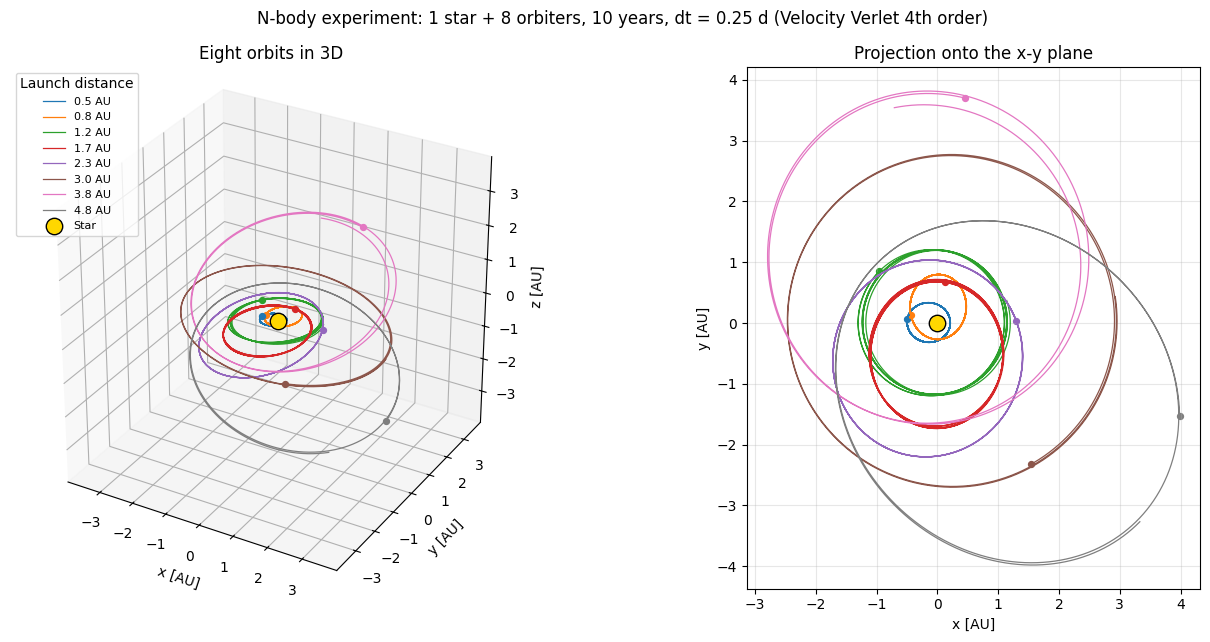

In [ ]:
"""
Experiment 1: eight bodies orbiting a single heavy central body (28/10/26).

Setup:
    - one central body (a solar mass) at the origin
    - eight light orbiters at different distances, placed at random angles
    - speeds from vel_init (random fraction of the circular speed => eccentric orbits)
    - directions from vel_direction (perpendicular to the radius vector)
    - integrated with run_vv_4 (Velocity Verlet 4th order)
No energy tracking yet; the output is purely the trajectories.
"""

# Re-seed so that re-running this cell reproduces exactly the same experiment
rnd.seed(256)


# A minimal body: mass, displacement, velocity and acceleration
class Body:
    def __init__(self, m, r):
        self.m = m
        self.r = np.array(r, dtype=float)
        self.v = np.zeros(3)
        self.a = np.zeros(3)


# Experiment parameters (SI units)
AU = 1.496e11   # astronomical unit [m]
M_SUN = 1.989e30    # solar mass [kg]
DAY = 86400.0   # [s]
e_soft = 1e7    # softening length [m] (negligible compared to the orbits)
dt = 0.25 * DAY     # timestep
steps_per_frame = 4    # one trajectory point is stored every 4 steps (1 day)
n_frames = 3650     # ten years of simulated time
xi_min = 0.6    # lowest allowed fraction of the circular speed (keeps e_orb <= 0.64)

orbit_radii_au = [0.5, 0.8, 1.2, 1.7, 2.3, 3.0, 3.8, 4.8]            # launch distances [AU]
orbit_masses = [3.3e23, 4.9e24, 6.0e24, 6.4e23, 1.9e27, 5.7e26, 8.7e25, 1.0e26]   # [kg]

# Initial conditions
star = Body(M_SUN, [0.0, 0.0, 0.0])
bodies = [star]

for r_au, m in zip(orbit_radii_au, orbit_masses):
    # Random direction on the sphere, restricted to +/- 20 degrees latitude (mild inclinations)
    phi = rnd.uniform(0.0, 2.0 * np.pi)
    lat = rnd.uniform(-np.radians(20), np.radians(20))
    pos = r_au * AU * np.array([np.cos(lat) * np.cos(phi), np.cos(lat) * np.sin(phi), np.sin(lat)])
    body = Body(m, pos)

    dist = euclidian_distance(body, star)   # distance to the star
    v_circ = np.sqrt(G_const * star.m / dist)   # circular speed at this distance
    speed = vel_init(star, G_const, dist)   # random fraction of v_circ
    while speed < xi_min * v_circ:      # redraw too-radial orbits (would need a tiny dt)
        speed = vel_init(star, G_const, dist)
    body.v = vel_direction(body, star, dist, speed) # perpendicular direction
    bodies.append(body)

    print(f"orbiter {len(bodies) - 1}: r = {dist / AU:4.2f} AU, xi = {speed / v_circ:4.2f}, "
          f"e_orb = {1 - (speed / v_circ) ** 2:4.2f}")

# Give the star the opposite total momentum so that the system does not drift away
star.v = -sum(b.m * b.v for b in bodies[1:]) / star.m

# Run the simulation, recording the displacement of every body
trajectories = [[b.r.copy()] for b in bodies]
for _ in range(n_frames):
    run_vv_4(bodies, G_const, e_soft, dt, steps_per_frame)
    for k, b in enumerate(bodies):
        trajectories[k].append(b.r.copy())

trajectories = np.array(trajectories) / AU      # shape: (N bodies, frames + 1, 3), in AU

# Plots
colours = plt.cm.tab10(np.arange(8))
fig = plt.figure(figsize=(14, 6.5))

# 3D view
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
for k in range(1, len(bodies)):
    x, y, z = trajectories[k].T
    ax3d.plot(x, y, z, color=colours[k - 1], lw=0.9, label=f"{orbit_radii_au[k - 1]} AU")
    ax3d.scatter(x[-1], y[-1], z[-1], color=colours[k - 1], s=18)
ax3d.scatter(0, 0, 0, color="gold", edgecolor="black", s=140, zorder=5, label="Star")

lim = np.abs(trajectories).max()
ax3d.set_xlim(-lim, lim)
ax3d.set_ylim(-lim, lim)
ax3d.set_zlim(-lim, lim)
ax3d.set_box_aspect((1, 1, 1))
ax3d.set_xlabel("x [AU]")
ax3d.set_ylabel("y [AU]")
ax3d.set_zlabel("z [AU]")
ax3d.set_title("Eight orbits in 3D")
ax3d.legend(title="Launch distance", fontsize=8, loc="upper left")

# Top-down projection (x-y plane)
ax2d = fig.add_subplot(1, 2, 2)
for k in range(1, len(bodies)):
    x, y, _ = trajectories[k].T
    ax2d.plot(x, y, color=colours[k - 1], lw=0.9)
    ax2d.scatter(x[-1], y[-1], color=colours[k - 1], s=18)
ax2d.scatter(0, 0, color="gold", edgecolor="black", s=140, zorder=5)
ax2d.set_aspect("equal")
ax2d.set_xlabel("x [AU]")
ax2d.set_ylabel("y [AU]")
ax2d.set_title("Projection onto the x-y plane")
ax2d.grid(alpha=0.3)

fig.suptitle(f"N-body experiment: 1 star + 8 orbiters, {n_frames * steps_per_frame * dt / DAY / 365.25:.0f} years, "
             f"dt = {dt / DAY:.2f} d (Velocity Verlet 4th order)")
plt.tight_layout()
plt.show()